
Random dropout
Linear RMSE: 0.00331261
Spline RMSE: 0.00053369

Periodic dropout
Linear RMSE: 0.00413643
Spline RMSE: 0.00110457

Block dropout
Linear RMSE: 0.02493858
Spline RMSE: 0.00475676


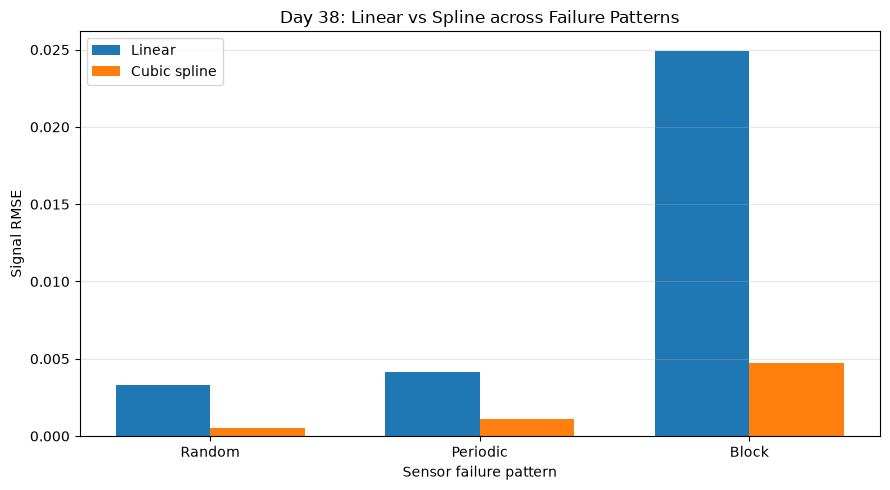

Random: spline RMSE reduction = 83.89%
Periodic: spline RMSE reduction = 73.30%
Block: spline RMSE reduction = 80.93%

Day 38 completed.
Plot saved to: ..\outputs\day38_failure_pattern_rmse.png
Results saved to: ..\outputs\day38_spline_failure_pattern_results.json


In [1]:

import json
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import interp1d, CubicSpline

# ==============================================
# Day 38: Linear vs Cubic Spline Failure Patterns
# ==============================================

output_dir = Path("../outputs")
output_dir.mkdir(parents=True, exist_ok=True)

# 1. Simulation parameters
num_sensors = 32
num_samples = 600

fs = 10e6
c = 1500.0
source_x = 5e-3
source_y = 20e-3
pulse_width = 1.5e-6

time = np.arange(num_samples) / fs
sensor_x = np.linspace(-15e-3, 15e-3, num_sensors)

# 2. Generate the original synthetic signals
signals_full = np.zeros((num_sensors, num_samples))

for i, sx in enumerate(sensor_x):
    distance = np.sqrt((sx - source_x)**2 + source_y**2)
    arrival_time = distance / c

    signals_full[i] = np.exp(
        -0.5 * ((time - arrival_time) / pulse_width)**2
    )

# 3. Define failure patterns: 8 inactive sensors in each case
rng = np.random.default_rng(42)

failure_patterns = {
    "Random": np.sort(
        rng.choice(num_sensors, size=8, replace=False)
    ),
    "Periodic": np.array(
        [1, 5, 9, 13, 17, 21, 25, 29]
    ),
    "Block": np.arange(12, 20)
}

def calculate_metrics(error):
    return {
        "MAE": float(np.mean(np.abs(error))),
        "RMSE": float(np.sqrt(np.mean(error**2))),
        "maximum_absolute_error": float(np.max(np.abs(error)))
    }

results = {
    "day": 38,
    "num_sensors": num_sensors,
    "num_inactive_sensors": 8,
    "missing_percentage": 25.0,
    "evaluation_region": "inactive sensor signals only",
    "patterns": {}
}

# 4. Evaluate both interpolation methods
for pattern_name, inactive_indices in failure_patterns.items():

    active_mask = np.ones(num_sensors, dtype=bool)
    active_mask[inactive_indices] = False

    active_x = sensor_x[active_mask]
    active_signals = signals_full[active_mask]

    # Linear interpolation
    linear_interpolator = interp1d(
        active_x,
        active_signals,
        kind="linear",
        axis=0,
        bounds_error=False,
        fill_value="extrapolate"
    )

    signals_linear = signals_full.copy()
    signals_linear[inactive_indices] = linear_interpolator(
        sensor_x[inactive_indices]
    )

    # Cubic spline interpolation
    spline_interpolator = CubicSpline(
        active_x,
        active_signals,
        axis=0,
        bc_type="natural",
        extrapolate=True
    )

    signals_spline = signals_full.copy()
    signals_spline[inactive_indices] = spline_interpolator(
        sensor_x[inactive_indices]
    )

    # Evaluate only the inactive sensors
    true_missing = signals_full[inactive_indices]

    linear_metrics = calculate_metrics(
        signals_linear[inactive_indices] - true_missing
    )

    spline_metrics = calculate_metrics(
        signals_spline[inactive_indices] - true_missing
    )

    results["patterns"][pattern_name] = {
        "inactive_indices": inactive_indices.tolist(),
        "linear": linear_metrics,
        "cubic_spline": spline_metrics
    }

    print(f"\n{pattern_name} dropout")
    print(f"Linear RMSE: {linear_metrics['RMSE']:.8f}")
    print(f"Spline RMSE: {spline_metrics['RMSE']:.8f}")

# 5. Plot RMSE for each pattern and method
pattern_names = list(failure_patterns.keys())

linear_rmse = [
    results["patterns"][name]["linear"]["RMSE"]
    for name in pattern_names
]

spline_rmse = [
    results["patterns"][name]["cubic_spline"]["RMSE"]
    for name in pattern_names
]

x = np.arange(len(pattern_names))
width = 0.35

fig, ax = plt.subplots(figsize=(9, 5))

ax.bar(
    x - width / 2,
    linear_rmse,
    width,
    label="Linear"
)

ax.bar(
    x + width / 2,
    spline_rmse,
    width,
    label="Cubic spline"
)

ax.set_xticks(x)
ax.set_xticklabels(pattern_names)
ax.set_xlabel("Sensor failure pattern")
ax.set_ylabel("Signal RMSE")
ax.set_title("Day 38: Linear vs Spline across Failure Patterns")
ax.legend()
ax.grid(axis="y", alpha=0.3)

fig.tight_layout()

fig.savefig(
    output_dir / "day38_failure_pattern_rmse.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# 6. Calculate relative RMSE reduction from spline
for pattern_name in pattern_names:
    linear_value = results["patterns"][pattern_name]["linear"]["RMSE"]
    spline_value = results["patterns"][pattern_name]["cubic_spline"]["RMSE"]

    if linear_value > 0:
        reduction = 100 * (linear_value - spline_value) / linear_value
    else:
        reduction = None

    results["patterns"][pattern_name]["spline_rmse_reduction_percent"] = (
        float(reduction) if reduction is not None else None
    )

    print(
        f"{pattern_name}: spline RMSE reduction = "
        f"{reduction:.2f}%"
    )

# 7. Save results
results_path = output_dir / "day38_spline_failure_pattern_results.json"

with open(results_path, "w", encoding="utf-8") as f:
    json.dump(results, f, indent=4, ensure_ascii=False)

print("\nDay 38 completed.")
print(f"Plot saved to: {output_dir / 'day38_failure_pattern_rmse.png'}")
print(f"Results saved to: {results_path}")
